In [1]:
import pandas as pd 


In [2]:
df = pd.read_csv("../data/processed/rotulado_v1.csv")  
df.columns = df.columns.str.lower()                       
df.to_csv("../data/processed/rotulado_v1.csv", index=False, encoding="utf-8")  
df.head()                                                 

,descricao,categoria,fonte,banco
0,Compra no débito - Jujuca Bomboniere Sao Berna...,Alimentação,conta,Inter
1,Compra no débito - Drogaria Sao Paulo 194sao B...,Saúde,conta,Inter
2,Pagamento efetuado - Pagamento Fatura - PESSOA,Outros,conta,Inter
3,Compra no débito - Coffee Break Mandu Ltdsao B...,Alimentação,conta,Inter
4,Pix recebido - PESSOA,Transferência,conta,Inter


In [3]:
df.shape
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 567 entries, 0 to 566
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   descricao  567 non-null    str  
 1   categoria  565 non-null    str  
 2   fonte      567 non-null    str  
 3   banco      567 non-null    str  
dtypes: str(4)
memory usage: 17.8 KB


In [4]:
df["categoria"]
df["categoria"].value_counts()

categoria
Alimentação      138
Outros           108
Compras           86
Transferência     55
Lazer             45
Mercado           43
Transporte        43
Saúde             29
Moradia            8
Assinaturas        8
Educação           2
Name: count, dtype: int64

<Axes: ylabel='categoria'>

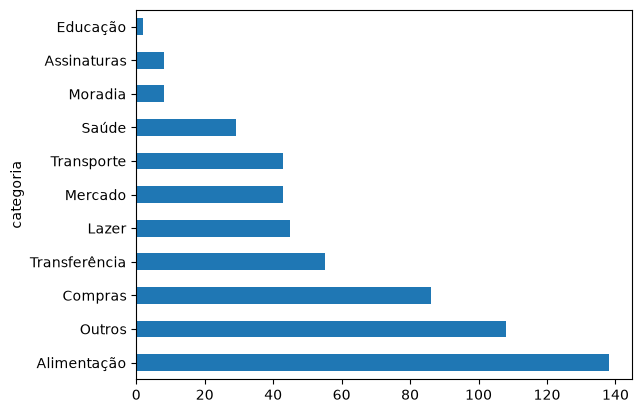

In [5]:
df["categoria"].value_counts().plot(kind="barh")

In [6]:
df[df["categoria"] == "Transporte"]

,descricao,categoria,fonte,banco
22,Compra no débito - Shopping Golden Squaresao B...,Transporte,conta,Inter
27,Compra no débito - Hs Metropole Sbc Sao Bernar...,Transporte,conta,Inter
34,Compra Meio De Transporte - No Estabelecimento...,Transporte,conta,Inter
52,Compra no débito - POSTO MONTE CARLO IGUA,Transporte,conta,Nubank
64,Compra no débito - PAYGO*PHD PARK,Transporte,conta,Nubank
81,Compra no débito - EMV CMT*,Transporte,conta,Nubank
103,PINPAG *AGDESP MUNICIP,Transporte,cartao,Bradesco
104,INPARK,Transporte,cartao,Bradesco
112,StereoCar 01/08,Transporte,cartao,Bradesco
114,SAVOL TOYOTA SBC 01/05,Transporte,cartao,Bradesco


In [7]:
df["tamanho"] = df["descricao"].str.len()
df.groupby("categoria")["tamanho"].mean()

categoria
Alimentação      44.195652
Assinaturas      18.375000
Compras          24.360465
Educação         27.000000
Lazer            23.311111
Mercado          31.860465
Moradia          41.250000
Outros           32.212963
Saúde            31.172414
Transferência    51.054545
Transporte       45.581395
Name: tamanho, dtype: float64

In [8]:
palavras = df["descricao"].str.upper().str.split().explode()
palavras.value_counts().head(15)

descricao
-                  334
NO                 263
COMPRA             210
DÉBITO             202
BRA                201
SAO                155
BERNARDO           111
ESTABELECIMENTO     61
PESSOA              51
PAULO               47
DE                  39
PIX                 36
TRANSFERÊNCIA       32
PELO                31
E                   30
Name: count, dtype: int64

In [9]:
df["fonte"].value_counts()

fonte
conta     287
cartao    280
Name: count, dtype: int64

In [12]:
pag = df['descricao'].str.contains("CORP", regex=False)
df[pag]

,descricao,categoria,fonte,banco,tamanho
559,CORPO E VIDA,Outros,cartao,Itaú,12


In [13]:
df["tamanho"] = df["descricao"].str.len()

media = df.groupby("categoria")["tamanho"].mean()

media.sort_values(ascending=False)

categoria
Transferência    51.054545
Transporte       45.581395
Alimentação      44.195652
Moradia          41.250000
Outros           32.212963
Mercado          31.860465
Saúde            31.172414
Educação         27.000000
Compras          24.360465
Lazer            23.311111
Assinaturas      18.375000
Name: tamanho, dtype: float64